### workshop_1: Adding Sunglasses to Your Passport Photo Using OpenCV
### Name: Parani Bala M
### Reg.no: 212224230192

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

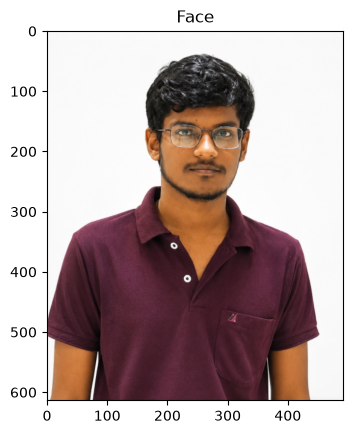

In [2]:
# Load the Face Image
faceImage = cv2.imread('My_Image.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")

In [3]:
faceImage.shape

(614, 493, 3)

Text(0.5, 1.0, 'glassPNG')

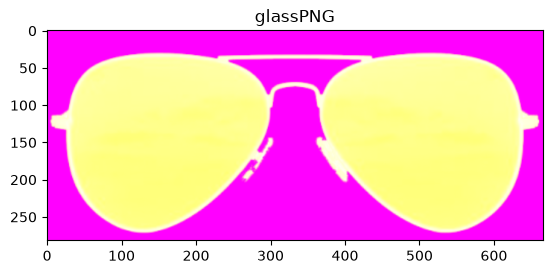

In [5]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [6]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG,(190,50))
print("image Dimension ={}".format(glassPNG.shape))

image Dimension =(50, 190, 4)


In [7]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

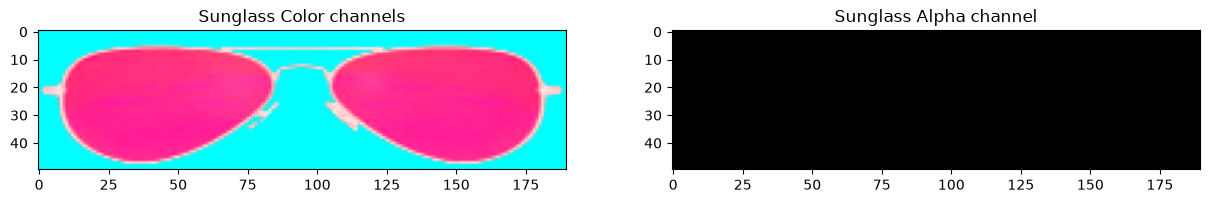

In [17]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels');
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel');

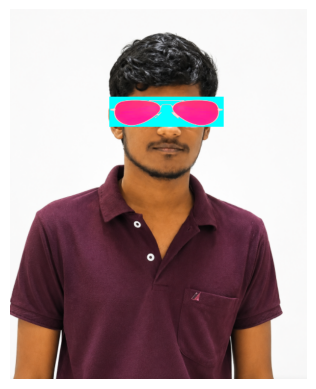

In [31]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Set the position of the glasses
x, y = 165, 145

# Get the glass dimensions
h, w = glassBGR.shape[:2]

# Resize if necessary
glassResized = cv2.resize(glassBGR, (190, 50))

# Replace the eye region
faceWithGlassesNaive[y:y+h, x:x+w] = glassResized

# Display the result
plt.imshow(faceWithGlassesNaive[...,::-1])
plt.axis('off')
plt.show()

Text(0.5, 1.0, 'Augmented Eye and Sunglass')

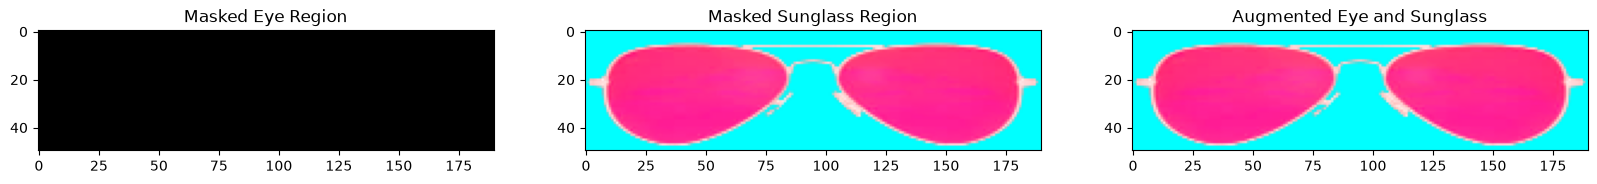

In [32]:
# Make the dimensions of the mask same as the input image.
# Since Face Image is a 3-channel image, we create a 3 channel image for the mask
glassMask = cv2.merge((glassMask1,glassMask1,glassMask1))

# Make the values [0,1] since we are using arithmetic operations
glassMask = np.uint8(glassMask/255)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Get the eye region from the face image
eyeROI= faceWithGlassesArithmetic[135:185,110:300]

# Use the mask to create the masked eye region
maskedEye = cv2.multiply(eyeROI,(1-  glassMask ))

# Use the mask to create the masked sunglass region
maskedGlass = cv2.multiply(glassBGR,glassMask)

# Combine the Sunglass in the Eye Region to get the augmented image
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)

# Display the intermediate results
plt.figure(figsize=[20,20])
plt.subplot(131);plt.imshow(maskedEye[...,::-1]);plt.title("Masked Eye Region")
plt.subplot(132);plt.imshow(maskedGlass[...,::-1]);plt.title("Masked Sunglass Region")
plt.subplot(133);plt.imshow(eyeRoiFinal[...,::-1]);plt.title("Augmented Eye and Sunglass")

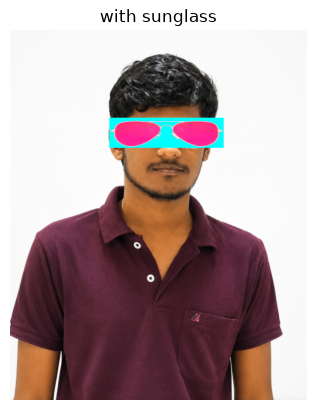

In [41]:
# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Set the position of the glasses
x, y = 165, 145

# Get the glass dimensions
h, w = glassBGR.shape[:2]

# Resize if necessary
glassResized = cv2.resize(glassBGR, (190, 50))

# Replace the eye region
faceWithGlassesNaive[y:y+h, x:x+w] = glassResized

# Display the result
# Load the Face Image
faceImage = cv2.imread('My_Image.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("with sunglass")
plt.imshow(faceWithGlassesNaive[...,::-1])
plt.axis('off')
plt.show()